# Gent Hyperelasticity — Unified Four-Model Comparison

One standalone notebook containing **Conventional NN**, **Sparse Conventional NN**, **PANN**, and **Sparse PANN**. Includes training, validation, extrapolation, RMSE heatmap, physical checks, and sparsity comparisons. Run cells from top to bottom.

The original uploaded notebook is unchanged.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import time
import copy

# Same hyperparameters as original notebook
mu = 0.8
jm = 40.0
Identity = torch.eye(3)
num_samples = 50000
lamda_min, lamda_max = 1.0, 4.0
eta_min, eta_max = 0.005, 0.03
m = 32
learning_rate = 0.01
num_epochs = 10000

torch.manual_seed(42)  # Reproducible comparison
import numpy as np
import pandas as pd
import seaborn as sns

# Same hard-concrete settings as uploaded sparsification notebook
beta, gamma, zeta, rho = 2/3, -0.1, 1.1, 3.5
log_interval = 100


In [2]:
# Original Gent stress and noise generation (unchanged equations)
def gent_stress_function(lamda, mu, jm):
    I1 = lamda**2 + 2/lamda
    stress = mu * (lamda - 1/lamda**2) / (1 - (I1 - 3)/jm)
    return stress

def deformation_gradient(lamda):
    diagonal_values = torch.stack([
        lamda,
        lamda**(-0.5),
        lamda**(-0.5)
    ], dim=-1)
    return torch.diag_embed(diagonal_values)

def frobenius_norm(F):
    return torch.sqrt(torch.sum((F - Identity)**2, dim=(-2, -1)))

def add_noise(P_true_train, eta_min, eta_max, lamda):
    P_char = torch.max(torch.abs(P_true_train))
    noise_sd_min = eta_min * P_char
    noise_sd_max = eta_max * P_char
    F = deformation_gradient(lamda)
    F_lambdamax = deformation_gradient(torch.max(lamda))
    q = 2.0
    t = frobenius_norm(F)
    ksy = torch.randn_like(P_true_train)
    conditional_noise_variance = torch.square(noise_sd_min) + (torch.square(noise_sd_max) - torch.square(noise_sd_min)) * ((t / frobenius_norm(F_lambdamax))**q)
    noise = torch.sqrt(conditional_noise_variance) * ksy
    return noise, conditional_noise_variance

def generate_synthetic_data(num_samples, lamda_min, lamda_max, eta_min, eta_max):
    lamda_train = torch.linspace(lamda_min, lamda_max, num_samples)
    I1_train = lamda_train**2 + 2/lamda_train
    P_true_train = gent_stress_function(lamda_train, mu, jm)
    noise, conditional_noise_variance = add_noise(P_true_train, eta_min, eta_max, lamda_train)
    Y_train = P_true_train + noise
    Y_train = Y_train.reshape(-1, 1)
    lamda_train = lamda_train.reshape(-1, 1)
    I1_train = I1_train.reshape(-1, 1)
    x = torch.cat((lamda_train, I1_train, Y_train), dim=1)
    return x, conditional_noise_variance

x, conditional_noise_variance = generate_synthetic_data(
    num_samples=50000, lamda_min=1.0, lamda_max=4.0,
    eta_min=0.005, eta_max=0.03
)


## Fixed training / validation partition (same samples for all four models)

In [3]:
indices = torch.randperm(len(x))
n_train = int(0.8 * len(x))
train_idx = indices[:n_train]
val_idx = indices[n_train:]

x_train = x[train_idx]
x_val = x[val_idx]
variance_train = conditional_noise_variance[train_idx].reshape(-1, 1)
variance_val = conditional_noise_variance[val_idx].reshape(-1, 1)

print('Training samples:', len(x_train))
print('Validation samples:', len(x_val))


Training samples: 40000
Validation samples: 10000


In [4]:
# Conventional neural network: stretch -> stress
class ConventionalNN(nn.Module):
    def __init__(self, m=32):
        super().__init__()
        self.fc1 = nn.Linear(1, m)
        self.fc2 = nn.Linear(m, 1)

    def forward(self, lamda):
        return self.fc2(F.softplus(self.fc1(lamda)))


# PANN: original softplus energy equation, without random sparsification gates
class PANN(nn.Module):
    def __init__(self, m=32):
        super().__init__()
        self.a = nn.Parameter(torch.randn(1))
        self.c = nn.Parameter(torch.randn(m))
        self.w = nn.Parameter(torch.randn(m))
        self.b = nn.Parameter(torch.randn(m))

    def forward(self, I1):
        a = F.softplus(self.a)
        c = F.softplus(self.c)
        w = F.softplus(self.w)
        b = self.b
        z = (I1 - 3) * w + b
        hidden = F.softplus(z) - F.softplus(b)
        psi = a * (I1 - 3) + torch.sum(c * hidden, dim=-1, keepdim=True)
        return psi


def pann_stress(model, lamda):
    I1 = (lamda**2 + 2 / lamda).detach().requires_grad_(True)
    psi = model(I1)
    dpsi_dI1 = torch.autograd.grad(
        psi, I1, grad_outputs=torch.ones_like(psi), create_graph=True
    )[0]
    return 2 * dpsi_dI1 * (lamda - 1 / lamda**2)


def predict_stress(model, lamda, is_pann):
    if is_pann:
        return pann_stress(model, lamda)
    return model(lamda)


## Hard-concrete sparse conventional NN
A gate is applied to every direct-stress network weight and bias. Training samples stochastic hard-concrete gates; validation/inference use deterministic stretched-sigmoid gates. The expected L0 penalty counts expected nonzero coefficients. This adaptation is not identical to sparsifying the PANN energy network.

In [6]:
# Sparse PANN: original energy architecture with Hard-Concrete gates on a, c, w, b.
# Deterministic gates are used at evaluation; random gates only during training.
class SparsePANN(nn.Module):
    def __init__(self, m=32, beta=2/3, gamma=-0.1, zeta=1.1):
        super().__init__()
        self.a = nn.Parameter(torch.randn(1))
        self.c = nn.Parameter(torch.randn(m))
        self.w = nn.Parameter(torch.randn(m))
        self.b = nn.Parameter(torch.randn(m))
        self.log_alpha_a = nn.Parameter(torch.randn(1))
        self.log_alpha_c = nn.Parameter(torch.randn(m))
        self.log_alpha_w = nn.Parameter(torch.randn(m))
        self.log_alpha_b = nn.Parameter(torch.randn(m))
        self.beta, self.gamma, self.zeta = beta, gamma, zeta

    def gate_logits(self):
        return [self.log_alpha_a, self.log_alpha_c,
                self.log_alpha_w, self.log_alpha_b]

    def gate(self, log_alpha, stochastic=True):
        if stochastic:
            u = torch.rand_like(log_alpha).clamp(1e-6, 1-1e-6)
            s = torch.sigmoid((torch.log(u) - torch.log1p(-u) + log_alpha) / self.beta)
        else:
            s = torch.sigmoid(log_alpha)
        return (s * (self.zeta - self.gamma) + self.gamma).clamp(0, 1)

    def forward(self, I1, stochastic=True):
        ga, gc, gw, gb = [self.gate(v, stochastic) for v in self.gate_logits()]
        a = F.softplus(self.a) * ga
        c = F.softplus(self.c) * gc
        w = F.softplus(self.w) * gw
        b = self.b * gb
        x = I1 - 3
        return a*x + (c * (F.softplus(x*w + b) - F.softplus(b))).sum(dim=-1, keepdim=True)

    def expected_active(self):
        offset = self.beta * np.log(-self.gamma/self.zeta)
        return sum(torch.sigmoid(v-offset).sum() for v in self.gate_logits())

    def active_count(self):
        return sum(int((self.gate(v, False)>0).sum().item()) for v in self.gate_logits())


In [7]:
class SparseConventionalNN(nn.Module):
    def __init__(self, m=32, beta=2/3, gamma=-0.1, zeta=1.1):
        super().__init__()
        self.fc1 = nn.Linear(1, m)
        self.fc2 = nn.Linear(m, 1)
        self.beta, self.gamma, self.zeta = beta, gamma, zeta
        self.log_alpha_w1 = nn.Parameter(torch.zeros_like(self.fc1.weight))
        self.log_alpha_b1 = nn.Parameter(torch.zeros_like(self.fc1.bias))
        self.log_alpha_w2 = nn.Parameter(torch.zeros_like(self.fc2.weight))
        self.log_alpha_b2 = nn.Parameter(torch.zeros_like(self.fc2.bias))

    def gate(self, log_alpha, stochastic=True):
        if stochastic:
            u = torch.rand_like(log_alpha).clamp(1e-6, 1-1e-6)
            s = torch.sigmoid((torch.log(u)-torch.log1p(-u)+log_alpha)/self.beta)
        else:
            s = torch.sigmoid(log_alpha)
        return (s*(self.zeta-self.gamma)+self.gamma).clamp(0,1)

    def forward(self, lamda, stochastic=True):
        w1 = self.fc1.weight * self.gate(self.log_alpha_w1, stochastic)
        b1 = self.fc1.bias * self.gate(self.log_alpha_b1, stochastic)
        w2 = self.fc2.weight * self.gate(self.log_alpha_w2, stochastic)
        b2 = self.fc2.bias * self.gate(self.log_alpha_b2, stochastic)
        return F.linear(F.softplus(F.linear(lamda, w1, b1)), w2, b2)

    def expected_active(self):
        offset = self.beta * np.log(-self.gamma/self.zeta)
        return sum(torch.sigmoid(a-offset).sum() for a in self.gate_logits())

    def gate_logits(self):
        return [self.log_alpha_w1, self.log_alpha_b1, self.log_alpha_w2, self.log_alpha_b2]

    def active_count(self):
        return sum(int((self.gate(a, stochastic=False)>0).sum()) for a in self.gate_logits())

# All models start from the same random seed; use independent model instances.
torch.manual_seed(42)
conventional_nn = ConventionalNN(m=m)
torch.manual_seed(42)
pann = PANN(m=m)
torch.manual_seed(42)
sparse_nn = SparseConventionalNN(m=m, beta=beta, gamma=gamma, zeta=zeta)
torch.manual_seed(42)
sparse_pann = SparsePANN(m=m, beta=beta, gamma=gamma, zeta=zeta)

for name, model in [('Conventional NN',conventional_nn),('Sparse Conventional NN',sparse_nn),('PANN',pann),('Sparse PANN',sparse_pann)]:
    print(f'{name}: {sum(p.numel() for p in model.parameters())} trainable scalars')
print('Sparse NN: 97 coefficients + 97 gate logits (before pruning)')
print("Sparse PANN: 97 coefficients + 97 gate logits")


Conventional NN: 97 trainable scalars
Sparse Conventional NN: 194 trainable scalars
PANN: 97 trainable scalars
Sparse PANN: 194 trainable scalars
Sparse NN: 97 coefficients + 97 gate logits (before pruning)
Sparse PANN: 97 coefficients + 97 gate logits


## Shared stress prediction, weighted loss, RMSE, and checkpoint selection
Training uses the original inverse-variance-weighted stress MSE. Reported RMSE is **unweighted** and comparable across models. Best checkpoints are selected by minimum validation RMSE, never by extrapolation.

In [8]:
def stress_prediction(model, lamda, kind, training=False):
    if kind == 'PANN':
        return pann_stress(model, lamda)
    if kind == 'Sparse PANN':
        I1 = (lamda**2 + 2/lamda).detach().requires_grad_(True)
        energy = model(I1, stochastic=training)
        dpsi = torch.autograd.grad(energy, I1, grad_outputs=torch.ones_like(energy), create_graph=True)[0]
        return 2*(lamda-lamda**(-2))*dpsi
    if kind in ('Sparse Conventional NN', 'Sparse PANN'):
        return model(lamda, stochastic=training)
    return model(lamda)

def stress_rmse(model, data, kind):
    # PANN requires autograd even during evaluation for d(energy)/dI1.
    with torch.enable_grad():
        pred = stress_prediction(model, data[:,0:1], kind, training=False)
        return torch.sqrt(torch.mean((pred-data[:,2:3])**2)).item()

def train_one(model, kind):
    opt = torch.optim.Adam(model.parameters(), lr=learning_rate)
    hist = {'epoch':[], 'train_rmse':[], 'val_rmse':[], 'seconds':[], 'expected_active':[]}
    best = {'val_rmse':float('inf'), 'epoch':None, 'weights':None}
    start = time.perf_counter()
    for ep in range(1, num_epochs+1):
        model.train()
        opt.zero_grad()
        pred = stress_prediction(model, x_train[:,0:1], kind, training=True)
        fit_loss = ((pred-x_train[:,2:3]).square()/variance_train).mean()
        penalty = rho*model.expected_active() if kind in ('Sparse Conventional NN', 'Sparse PANN') else 0.0
        loss = fit_loss + penalty
        loss.backward()
        opt.step()

        if ep == 1 or ep % log_interval == 0 or ep == num_epochs:
            model.eval()
            tr = stress_rmse(model, x_train, kind)
            va = stress_rmse(model, x_val, kind)
            hist['epoch'].append(ep)
            hist['train_rmse'].append(tr)
            hist['val_rmse'].append(va)
            hist['seconds'].append(time.perf_counter()-start)
            hist['expected_active'].append(model.expected_active().item() if kind in ('Sparse Conventional NN', 'Sparse PANN') else np.nan)
            if va < best['val_rmse']:
                best = {'val_rmse':va, 'epoch':ep, 'weights':copy.deepcopy(model.state_dict())}
            if ep == 1 or ep % 1000 == 0 or ep == num_epochs:
                print(f'{kind:25s} epoch {ep:5d} | train RMSE {tr:.5f} | val RMSE {va:.5f}')
    model.load_state_dict(best['weights'])
    model.eval()
    print(f'Best checkpoint for {kind}: epoch {best["epoch"]}, val RMSE {best["val_rmse"]:.6f}')
    return hist, best

# To do a quick smoke test, temporarily set num_epochs=3 above, then restore 10000 for the full experiment.
results = {}
for name, model in [('Conventional NN',conventional_nn),('Sparse Conventional NN',sparse_nn),('PANN',pann),('Sparse PANN',sparse_pann)]:
    print('\nTraining',name)
    history, best = train_one(model, name)
    results[name] = {'model':model, 'history':history, 'best':best}
print('Sparse PANN: 97 energy coefficients + 97 gate logits (before pruning)')



Training Conventional NN
Conventional NN           epoch     1 | train RMSE 3.42966 | val RMSE 3.44104
Conventional NN           epoch  1000 | train RMSE 0.14993 | val RMSE 0.14979
Conventional NN           epoch  2000 | train RMSE 0.14883 | val RMSE 0.14874
Conventional NN           epoch  3000 | train RMSE 0.14436 | val RMSE 0.14452
Conventional NN           epoch  4000 | train RMSE 0.11132 | val RMSE 0.11146
Conventional NN           epoch  5000 | train RMSE 0.09805 | val RMSE 0.09814
Conventional NN           epoch  6000 | train RMSE 0.09328 | val RMSE 0.09328
Conventional NN           epoch  7000 | train RMSE 0.09222 | val RMSE 0.09247
Conventional NN           epoch  8000 | train RMSE 0.09010 | val RMSE 0.09021
Conventional NN           epoch  9000 | train RMSE 0.08945 | val RMSE 0.08958
Conventional NN           epoch 10000 | train RMSE 0.08907 | val RMSE 0.08923
Best checkpoint for Conventional NN: epoch 10000, val RMSE 0.089226

Training Sparse Conventional NN
Sparse Conventi

## Figure 1 — Training and validation RMSE on the same axes

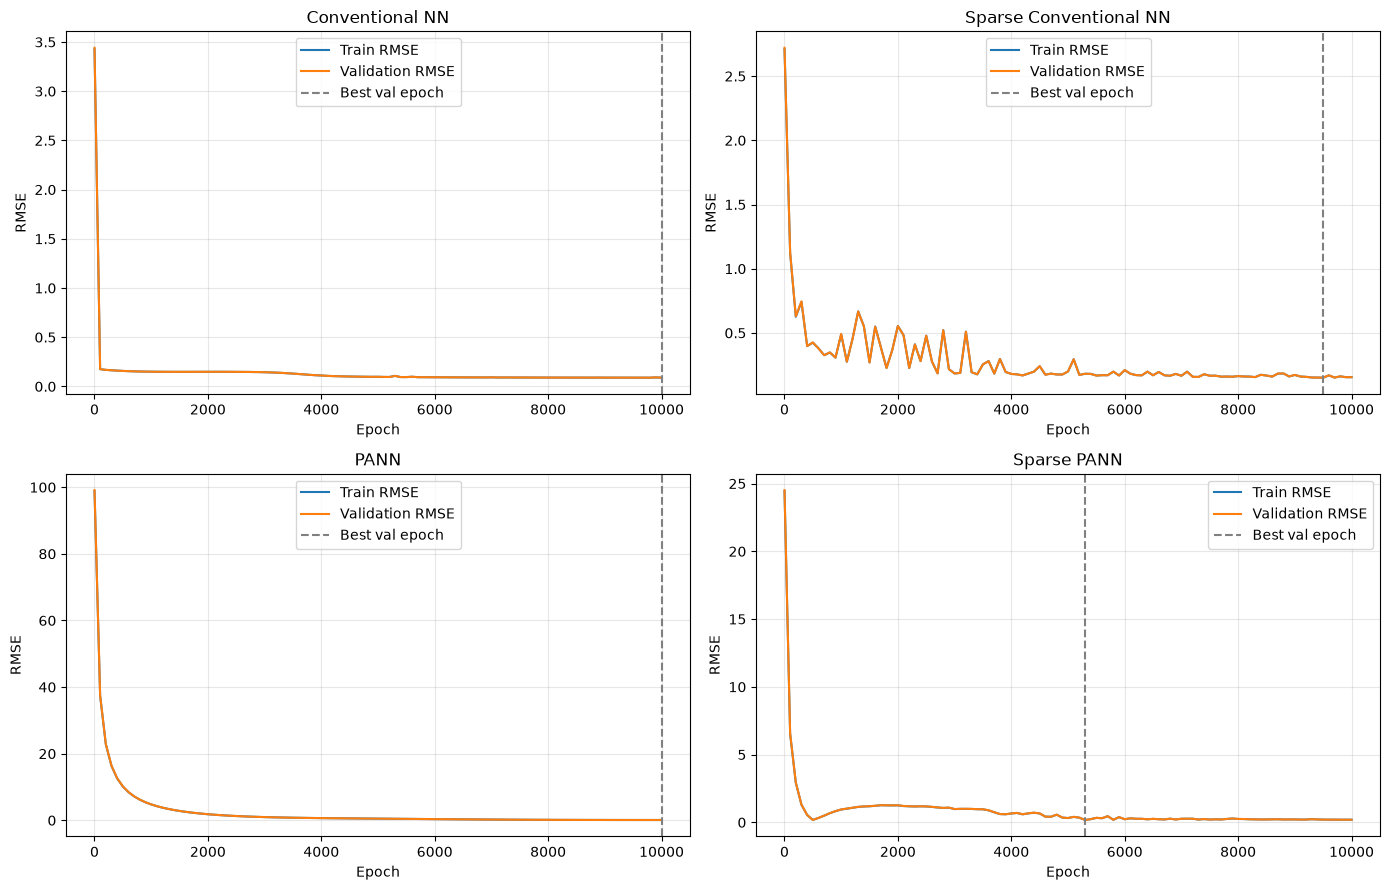

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14,9), sharey=False)
for ax,(name,res) in zip(axes.flat, results.items()):
    h=res['history']
    ax.plot(h['epoch'],h['train_rmse'],label='Train RMSE')
    ax.plot(h['epoch'],h['val_rmse'],label='Validation RMSE')
    ax.axvline(res['best']['epoch'],color='gray',linestyle='--',label='Best val epoch')
    ax.set(title=name,xlabel='Epoch',ylabel='RMSE')
    ax.legend();ax.grid(alpha=.3)
plt.tight_layout();plt.show()

## Figure 2 — Stress–stretch curves and absolute errors (clean Gent reference)

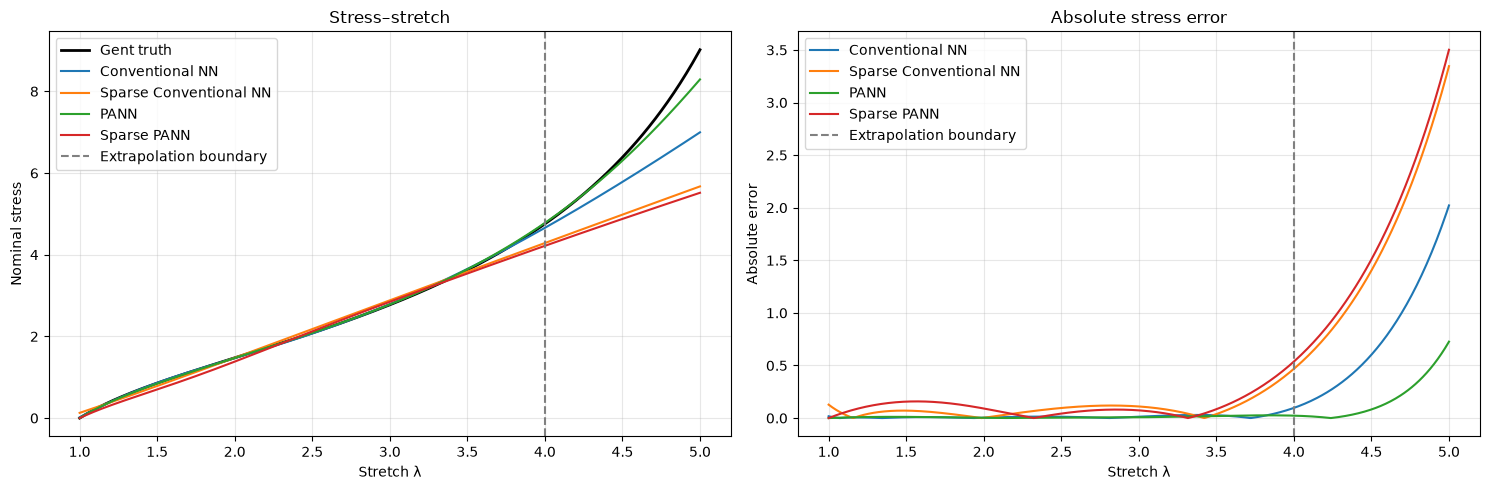

In [10]:
lamda_plot = torch.linspace(1.0, 5.0, 500).reshape(-1,1)
P_true = gent_stress_function(lamda_plot,mu,jm).detach()
predictions = {}
for name,res in results.items():
    predictions[name] = stress_prediction(res['model'],lamda_plot,name,training=False).detach()

fig,axes=plt.subplots(1,2,figsize=(15,5))
axes[0].plot(lamda_plot.numpy(),P_true.numpy(),color='black',lw=2,label='Gent truth')
for name,pred in predictions.items():
    axes[0].plot(lamda_plot.numpy(),pred.numpy(),label=name)
    axes[1].plot(lamda_plot.numpy(),(pred-P_true).abs().numpy(),label=name)
for ax in axes:
    ax.axvline(4,color='gray',ls='--',label='Extrapolation boundary')
    ax.set_xlabel('Stretch λ');ax.grid(alpha=.3);ax.legend()
axes[0].set(ylabel='Nominal stress',title='Stress–stretch')
axes[1].set(ylabel='Absolute error',title='Absolute stress error')
plt.tight_layout();plt.show()

## Figure 3 — RMSE heatmap: train, validation, extrapolation
Train and validation are measured against **noisy observed stress**, while extrapolation is measured against the **clean Gent curve** in (4,5]. All use restored best-validation checkpoints.

                        Training  Validation  Extrapolation
Model                                                      
Conventional NN         0.089066    0.089226       0.934075
Sparse Conventional NN  0.151711    0.151625       1.777182
PANN                    0.087448    0.087806       0.266651
Sparse PANN             0.174469    0.174424       1.884783


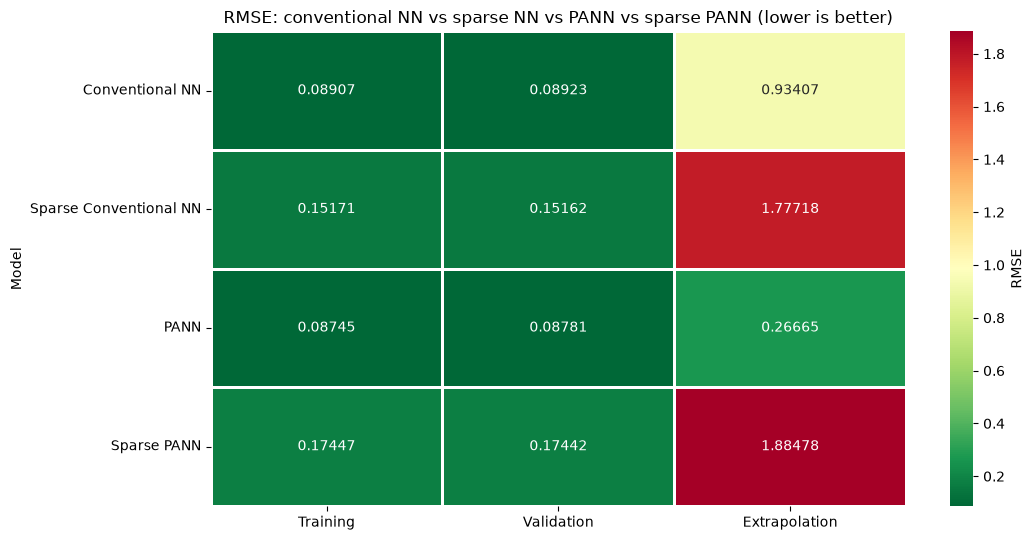

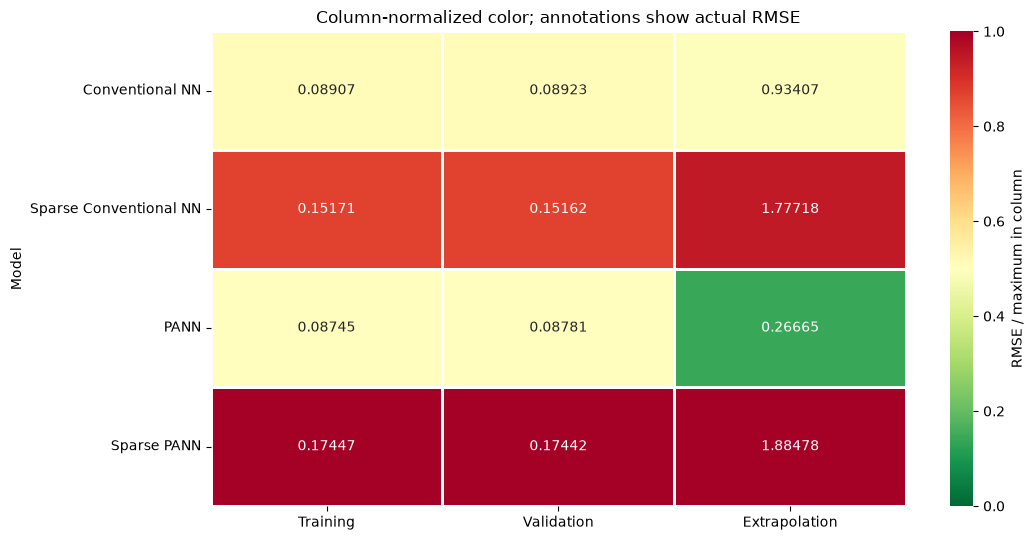

In [11]:
mask = lamda_plot[:,0]>4.0
rows=[]
for name,res in results.items():
    model=res['model']
    tr=stress_rmse(model,x_train,name)
    va=stress_rmse(model,x_val,name)
    ex=torch.sqrt(torch.mean((predictions[name][mask]-P_true[mask]).square())).item()
    rows.append({'Model':name,'Training':tr,'Validation':va,'Extrapolation':ex})
rmse_df=pd.DataFrame(rows).set_index('Model')
print(rmse_df.round(6))
plt.figure(figsize=(11,5.5))
sns.heatmap(rmse_df,annot=True,fmt='.5f',cmap='RdYlGn_r',linewidths=1,cbar_kws={'label':'RMSE'})
plt.title('RMSE: conventional NN vs sparse NN vs PANN vs sparse PANN (lower is better)')
plt.tight_layout();plt.show()

# Within-column normalized heatmap: makes the smaller train/validation differences visible
scaled=rmse_df.div(rmse_df.max(axis=0),axis=1)
plt.figure(figsize=(11,5.5))
sns.heatmap(scaled,annot=rmse_df.round(5),fmt='',cmap='RdYlGn_r',vmin=0,vmax=1,linewidths=1,
            cbar_kws={'label':'RMSE / maximum in column'})
plt.title('Column-normalized color; annotations show actual RMSE')
plt.tight_layout();plt.show()

## Figure 4 — Training efficiency and sparsity

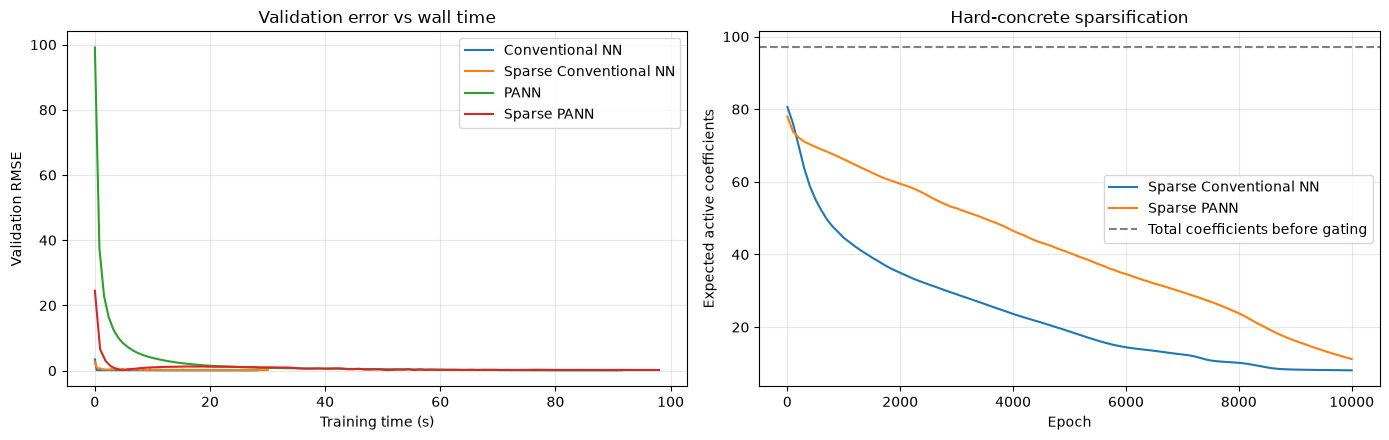

Sparse NN deterministic nonzero coefficients: 8 of 97
Sparse PANN deterministic nonzero coefficients: 51 of 97


In [12]:
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
for name,res in results.items():
    h=res['history']
    axes[0].plot(h['seconds'],h['val_rmse'],label=name)
axes[0].set(xlabel='Training time (s)',ylabel='Validation RMSE',title='Validation error vs wall time')
axes[0].grid(alpha=.3);axes[0].legend()
for sparse_name in ['Sparse Conventional NN', 'Sparse PANN']:
    h=results[sparse_name]['history']
    axes[1].plot(h['epoch'],h['expected_active'],label=sparse_name)
axes[1].axhline(97,color='gray',ls='--',label='Total coefficients before gating')
axes[1].set(xlabel='Epoch',ylabel='Expected active coefficients',title='Hard-concrete sparsification')
axes[1].grid(alpha=.3);axes[1].legend()
plt.tight_layout();plt.show()
print('Sparse NN deterministic nonzero coefficients:',sparse_nn.active_count(),'of 97')
print("Sparse PANN deterministic nonzero coefficients:", sparse_pann.active_count(), "of 97")


## Figure 5 — Physical consistency and compact results

In [13]:
summary=[]
for name,res in results.items():
    pred=predictions[name]
    slope=(pred[1:]-pred[:-1])/(lamda_plot[1:]-lamda_plot[:-1])
    summary.append({'Model':name,'Best epoch':res['best']['epoch'],
                    'Train RMSE':rmse_df.loc[name,'Training'],
                    'Validation RMSE':rmse_df.loc[name,'Validation'],
                    'Extrapolation RMSE':rmse_df.loc[name,'Extrapolation'],
                    'P(1)':float(pred[0].item()),
                    'Negative slopes':int((slope<0).sum().item()),
                    'Train time (s)':res['history']['seconds'][-1],
                    'Trainable scalars':sum(p.numel() for p in res['model'].parameters())})
summary_df=pd.DataFrame(summary).set_index('Model')
print(summary_df.round(5).to_string())
print('\nBest validation RMSE:',rmse_df['Validation'].idxmin())
print('Best extrapolation RMSE:',rmse_df['Extrapolation'].idxmin())
print('Note: use extrapolation only for final evaluation, not for checkpoint/hyperparameter selection.')
print('Sparse PANN deterministic nonzero coefficients:',sparse_pann.active_count(),'of 97')


                        Best epoch  Train RMSE  Validation RMSE  Extrapolation RMSE     P(1)  Negative slopes  Train time (s)  Trainable scalars
Model                                                                                                                                           
Conventional NN              10000     0.08907          0.08923             0.93407  0.01732                0        28.19733                 97
Sparse Conventional NN        9500     0.15171          0.15162             1.77718  0.12760                0        30.04833                194
PANN                         10000     0.08745          0.08781             0.26665  0.00000                0        91.57153                 97
Sparse PANN                   5300     0.17447          0.17442             1.88478  0.00000                0        98.00610                194

Best validation RMSE: PANN
Best extrapolation RMSE: PANN
Note: use extrapolation only for final evaluation, not for checkpoint/hy

## Interpretation and limitations

- **Conventional vs PANN:** isolates physics augmentation (with comparable 97 constitutive coefficients).
- **Conventional vs Sparse Conventional:** isolates a particular hard-concrete sparsification method; the sparse network optimizes 97 gate logits in addition to its 97 coefficients.
- **Sparse Conventional vs PANN:** compares two different inductive biases, but not a full factorial experiment. To isolate their interaction, add a **fourth, sparse PANN**.
- **Do not claim overfitting solely because validation RMSE wiggles**; look for a sustained rise while training RMSE decreases.
- **Sparse gates use a deterministic approximation for evaluation**; expected active count is probabilistic and not the same as the deterministic nonzero count.
- **Training/validation RMSE target noisy measurements**; extrapolation RMSE targets clean Gent stress. Interpret their scales accordingly.
- **ρ=3.5 may over-penalize the direct-stress network**; tune only using validation data if necessary, and report the change.
- For a stronger statistical conclusion, repeat training over multiple random seeds and report means and variability.

### Interpretation

- Conventional NN vs PANN: effect of physics augmentation without sparsity.
- Sparse Conventional NN vs Sparse PANN: effect of physics augmentation with sparsity.
- Conventional NN vs Sparse Conventional NN: effect of sparsity without physics.
- PANN vs Sparse PANN: effect of sparsity with physics.

The original Gent data-generation equations and hyperparameters are unchanged. Sparse models use the same `rho=3.5` penalty; this is a controlled starting point, not proof that the same penalty is optimal for both architectures. All metrics are evaluated after restoring each model's best validation checkpoint. Extrapolation data are used only for final evaluation.